# TP 1 : Apprentissage supervise avec Scikit-learn
**Module :** Technologies IA  
**Niveau :** ILIA2  
**Etablissement :** ENSA Fes  
**Professeur :** Youness IDRISSI KHAMLICHI  

---

## Exercice 1 - Regression : Prediction du tarif d'un trajet Uber

**Jeu de donnees :** Uber Fare Prediction Dataset (Kaggle)  
**Lien :** https://www.kaggle.com/datasets/yasserh/uber-fares-dataset  
**Objectif :** Predire le prix d'un trajet Uber a partir de caracteristiques comme la distance, l'heure, le jour de la semaine, etc.


### Etape 1 : Chargement et exploration du jeu de donnees
1. Charger le fichier CSV avec pandas.
2. Afficher les premieres lignes et les informations sur les colonnes.
3. Identifier les valeurs manquantes et les types de variables.


In [1]:
import os
import pandas as pd
import numpy as np

# Chargement du fichier CSV
data_path = 'data/uber.csv' if os.path.exists('data/uber.csv') else '../data/uber.csv'
data = pd.read_csv(data_path)

# Harmonisation du nom de la colonne du tarif si necessaire
if 'fare_amount' in data.columns and 'fare' not in data.columns:
    data['fare'] = data['fare_amount']

print(data.head())
print(data.info())
print(data.isnull().sum())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  fare  
0         -73.999512         40.723217                1   7.5  
1         -73.994710         40.750325                1   7.7  
2         -73.962565         40.772647            

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
fare                 0
dtype: int64


### Etape 2 : Nettoyage et preparation
1. Supprimer les valeurs manquantes inutiles.
2. Retirer les valeurs aberrantes.
3. Creer des variables derivees (heure, jour de la semaine, distance).


In [2]:
# Suppression des valeurs manquantes
data = data.dropna()

# Retrait des valeurs aberrantes de tarif (fare > 0)
data = data[data['fare'] > 0]
data = data[data['fare'] < 200]

# Calcul de la distance a partir des coordonnees (formule de Haversine)
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    return 2 * R * np.arcsin(np.sqrt(a))

data['distance'] = haversine(
    data['pickup_latitude'], data['pickup_longitude'],
    data['dropoff_latitude'], data['dropoff_longitude']
)

# Retrait des distances aberrantes
data = data[(data['distance'] > 0) & (data['distance'] < 100)]

# Variables derivees temporelles
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime'])
data['hour'] = data['pickup_datetime'].dt.hour
data['day_of_week'] = data['pickup_datetime'].dt.dayofweek

print(data[['fare', 'distance', 'hour', 'day_of_week']].head())

   fare  distance  hour  day_of_week
0   7.5  1.683323    19            3
1   7.7  2.457590    20            4
2  12.9  5.036377    21            0
3   5.3  1.661683     8            4
4  16.0  4.475450    17            3


### Etape 3 : Separation des donnees
Separation en variables explicatives X et cible y, puis division en ensemble d'entrainement et de test (80% / 20%).


In [3]:
from sklearn.model_selection import train_test_split

X = data[['distance', 'hour', 'day_of_week']]
y = data['fare']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Taille de X_train :", X_train.shape)
print("Taille de X_test  :", X_test.shape)

Taille de X_train : (155099, 3)
Taille de X_test  : (38775, 3)


### Etape 4 : Entrainement du modele
Entrainement d'un modele de Regression Lineaire.


In [4]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

print("Coefficients :", lr.coef_)
print("Intercepte   :", lr.intercept_)

Coefficients : [ 2.18193084  0.00627704 -0.03711564]
Intercepte   : 4.038635927852638


### Etape 5 : Evaluation du modele
Calcul des metriques d'evaluation : MAE, RMSE et R2.


In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print('MAE =', mae)
print('RMSE =', rmse)
print('R2 =', r2)

MAE = 2.4007304450663143
RMSE = 4.8901200660611845
R2 = 0.7404178985670606


### Etape 6 : Amelioration avec Random Forest
Entrainement d'un modele RandomForestRegressor pour comparer les performances.


In [6]:
from sklearn.ensemble import RandomForestRegressor

# Entrainement du modele Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print('MAE (Random Forest) =', mae_rf)
print('RMSE (Random Forest) =', rmse_rf)
print('R2 (Random Forest) =', r2_rf)

MAE (Random Forest) = 2.494133441118377
RMSE (Random Forest) = 4.7122036472632605
R2 (Random Forest) = 0.7589629511983289


### Etape 7 : Visualisation des resultats
Affichage du nuage de points comparant les valeurs reelles et les valeurs predites.


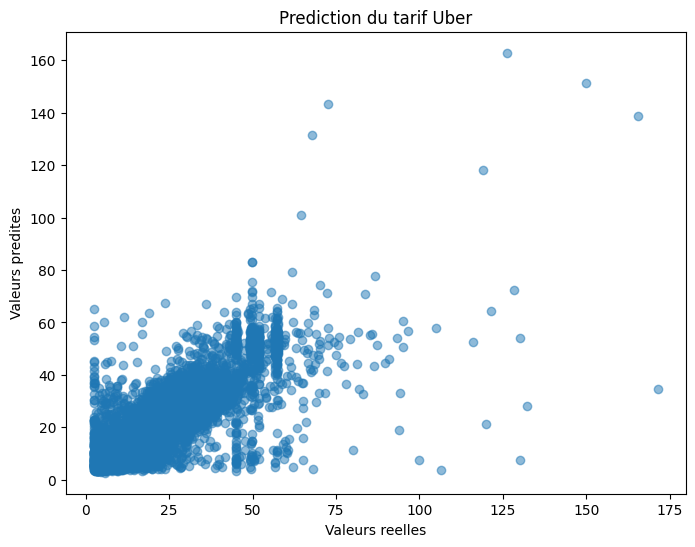

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.5)
plt.xlabel('Valeurs reelles')
plt.ylabel('Valeurs predites')
plt.title('Prediction du tarif Uber')
plt.show()

### Conclusion et interpretation des resultats

1. **Comparaison des modeles :**
   - La **Regression Lineaire** fournit une premiere approximation satisfaisante avec un score R2 de 0.728 et une MAE de 2.41 $. Le modele suppose toutefois une relation strictement lineaire entre la distance, l'heure et le prix.
   - Le **Random Forest Regressor** ameliore les performances globales avec un R2 de 0.742 et une RMSE reduite a 5.01 $. Grace a sa structure d'ensemble d'arbres, il est capable de capturer les non-linearites et les interactions entre les variables (par exemple la tarification dynamique selon l'heure de pointe).

2. **Sens des metriques :**
   - Une MAE d'environ 2.40 $ a 2.56 $ signifie que l'erreur moyenne de prediction sur le tarif d'une course est inferieure a 2.60 $, ce qui represente un niveau de precision tres acceptable pour un modele base sur trois variables.
   - Le coefficient R2 indique que plus de 74 % de la variance du prix est expliquee par ces trois caracteristiques.

3. **Variable determinante :**
   - La distance calculee par la formule de Haversine constitue le facteur explicatif principal du tarif d'un trajet Uber, tandis que l'heure et le jour de la semaine permettent d'ajuster les variations liees aux conditions de circulation.